In [ ]:
from cyvcf2 import VCF

vcf_path = "/mnt/d/thesis/data/clinvar_selected_variants.vcf"
vcf_reader = VCF(vcf_path)

# Samples for inspection
for i, variant in enumerate(vcf_reader):
    print(f"Variant {i+1}:")
    print("  CHROM:", variant.CHROM)
    print("  POS:", variant.POS)
    print("  REF:", variant.REF)
    print("  ALT:", variant.ALT)
    print("  INFO:", variant.INFO)
    print("-" * 50)
    if i >= 4:
        break


In [ ]:
vcf_reader = VCF(vcf_path)  # Reload each time

for i, variant in enumerate(vcf_reader):
    info_dict = dict(variant.INFO)  # Transform INFO into dict
    print(f"Variant {i+1} INFO fields:")
    for key, value in info_dict.items():
        print(f"  {key}: {value}")
    print("-" * 50)
    if i >= 4:
        break


In [ ]:
# Inspect unique values in CLNSIG and CLNDN to determain filtering strategy for next step
import pandas as pd
vcf_reader = VCF(vcf_path)

# Initialize sets
clnsig_values = set()
clndn_values = set()

# Unique values
for i, variant in enumerate(vcf_reader):
    clnsig = variant.INFO.get("CLNSIG")
    clndn = variant.INFO.get("CLNDN")
    
    if clnsig:
        clnsig_values.add(clnsig)
    if clndn:
        clndn_values.add(clndn)

list(sorted(clnsig_values)), list(sorted(clndn_values))



In [ ]:
# Save to csv for further inspection
df_clndn = pd.DataFrame(sorted(clndn_values), columns=["CLNDN"])
df_clndn.to_csv("unique_clndn_values.csv", index=False)

In [ ]:
import re

vcf_reader = VCF(vcf_path)
filtered_variants = []

for variant in vcf_reader:
    clnsig = variant.INFO.get("CLNSIG", "")
    clndn = variant.INFO.get("CLNDN", "")
    
    # Filter with key words: benign/pathogenic, and breast cancer
    if (
        isinstance(clnsig, str) and isinstance(clndn, str) and
        re.search(r"benign|pathogenic", clnsig, re.IGNORECASE) and
        re.search(r"breast", clndn, re.IGNORECASE)
    ):
        filtered_variants.append({
            "CHROM": variant.CHROM,
            "POS": variant.POS,
            "REF": variant.REF,
            "ALT": ",".join(variant.ALT),
            "CLNSIG": clnsig,
            "CLNDN": clndn
        })

print(f"Total filtered variants: {len(filtered_variants)}")

for v in filtered_variants[:5]:
    print(v)


In [ ]:
from cyvcf2 import VCF

vcf_path = "../data/clinvar_selected_variants.vcf"

vcf_reader = VCF(vcf_path)

count = 0
for v in vcf_reader:
    clnsig = v.INFO.get("CLNSIG", "")
    clndn = v.INFO.get("CLNDN", "")
    if "breast" in clndn.lower():
        print("CLNDN:", clndn)
        print("CLNSIG:", clnsig)
        print("-" * 40)
        count += 1
        if count >= 10:
            break


## Second try

In [9]:
from cyvcf2 import VCF
from collections import Counter

# load vcf
vcf_path = "../data/clinvar_selected_variants.vcf"
vcf_reader = VCF(vcf_path)

# initiate counter
clnsig_counter = Counter()

# find unique value and counte
for variant in vcf_reader:
    clnsig = variant.INFO.get("CLNSIG")
    if clnsig:
        clnsig_str = str(clnsig).strip()
        clnsig_counter[clnsig_str] +=1

vcf_reader.close()

# print
print("Unique CLNSIG values and their counts:")
for clnsig_value, count in clnsig_counter.most_common():
    print(f"{clnsig_value}: {count}")

Unique CLNSIG values and their counts:
Conflicting_classifications_of_pathogenicity: 7675
Likely_benign: 6109
Pathogenic: 2019
Benign/Likely_benign: 1653
Benign: 1556
Pathogenic/Likely_pathogenic: 667
Likely_pathogenic: 420
Uncertain_significance: 1
not_provided: 1
Conflicting_classifications_of_pathogenicity|risk_factor: 1


In [10]:
# further filter
from cyvcf2 import VCF, Writer

## define vcf files paths
vcf_path = "../data/clinvar_selected_variants.vcf"
output_vcf_path = "../data/clinvar_bc_variants_for_vep.vcf"

## define labled allowed in CLNSIG
allowed_labels = [
    "Likely_benign",
    "Pathogenic",
    "Benign/Likely_benign",
    "Benign",
    "Pathogenic/Likely_pathogenic",
    "Likely_pathogenic"
]

## initiate VCF reader and writer
vcf_reader = VCF(vcf_path)
vcf_writer = Writer(output_vcf_path, vcf_reader)

## filtering
for variant in vcf_reader:
    clnsig = variant.INFO.get("CLNSIG")
    if clnsig is not None:
        clnsig_str = str(clnsig).strip() # clean string
        if clnsig_str in allowed_labels:
            vcf_writer.write_record(variant)

## close
vcf_reader.close()
vcf_writer.close()

## note
print("Filtering has been done, all qualified variants are in: ", output_vcf_path)

Filtering has been done, all qualified variants are in:  ../data/clinvar_bc_variants_for_vep.vcf


In [11]:
from cyvcf2 import VCF
from collections import Counter

# load vcf
vcf_path = "../data/clinvar_bc_variants_for_vep.vcf"
vcf_reader = VCF(vcf_path)

# initiate counter
clnsig_counter = Counter()

# find unique value and counte
for variant in vcf_reader:
    clnsig = variant.INFO.get("CLNSIG")
    if clnsig:
        clnsig_str = str(clnsig).strip()
        clnsig_counter[clnsig_str] +=1

vcf_reader.close()

# print
print("Unique CLNSIG values and their counts:")
for clnsig_value, count in clnsig_counter.most_common():
    print(f"{clnsig_value}: {count}")

Unique CLNSIG values and their counts:
Likely_benign: 6109
Pathogenic: 2019
Benign/Likely_benign: 1653
Benign: 1556
Pathogenic/Likely_pathogenic: 667
Likely_pathogenic: 420


## Transcript harmonization

**Not conducted**

In [3]:
import pandas as pd

# Load data
df = pd.read_csv('../data/clinvar_bc_annotated.txt', sep='\t', skiprows=93)

# Check contents and headings
print(df.columns.tolist())
print(df.head())

/tmp/ipykernel_786/3405604441.py:4: DtypeWarning: Columns (7) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('../data/clinvar_bc_annotated.txt', sep='\t', skiprows=93)


['#Uploaded_variation', 'Location', 'Allele', 'Gene', 'Feature', 'Feature_type', 'Consequence', 'cDNA_position', 'CDS_position', 'Protein_position', 'Amino_acids', 'Codons', 'Existing_variation', 'IMPACT', 'DISTANCE', 'STRAND', 'FLAGS', '1000Gp3_AF', 'AllofUs_ALL_AF', 'AlphaMissense_score', 'BayesDel_addAF_score', 'BayesDel_noAF_score', 'CADD_raw', 'ClinPred_score', 'DANN_score', 'DEOGEN2_score', 'ESM1b_score', 'Eigen-PC-raw_coding', 'Eigen-raw_coding', 'GERP++_RS', 'GERP_91_mammals', 'LIST-S2_score', 'M-CAP_score', 'MPC_score', 'MVP_score', 'MetaLR_score', 'MetaRNN_score', 'MetaSVM_score', 'MutFormer_score', 'MutPred_score', 'MutScore_score', 'MutationAssessor_score', 'MutationTaster_score', 'PHACTboost_score', 'PROVEAN_score', 'Polyphen2_HDIV_score', 'Polyphen2_HVAR_score', 'PrimateAI_score', 'REVEL_score', 'RegeneronME_ALL_AF', 'SIFT4G_score', 'SIFT_score', 'TOPMed_frz8_AF', 'VARITY_ER_LOO_score', 'VARITY_ER_score', 'VARITY_R_LOO_score', 'VARITY_R_score', 'VEST4_score', 'bStatistic'

In [4]:
df.columns = df.columns.str.lstrip('#') # remove # from colums' name

print('CANONICAL' in df.columns)

False


## Populazation frequency filtering

In [5]:
print(df['dbNSFP_POPMAX_AF'].head())

0    -
1    -
2    -
3    -
4    -
Name: dbNSFP_POPMAX_AF, dtype: object


In [7]:
df['dbNSFP_POPMAX_AF'] = pd.to_numeric(df['dbNSFP_POPMAX_AF'], errors='coerce')

AF_threshold = 0.01

df_rare = df[df['dbNSFP_POPMAX_AF'] < AF_threshold]

print(f'There are {len(df_rare)} items after filtering')

There are 20500 items after filtering


In [20]:
# Deduplication

grouped = df_rare.groupby('Uploaded_variation')

sampled = grouped.apply(lambda x: x.sample(1), include_groups=False)

df_rare_unique = sampled.reset_index()

print(f"There are {len(df_rare_unique)} unique items after deduplication.")

There are 1368 unique items after deduplication.


Since there are few items left after filtering, a histogram is plotted for reasoning.

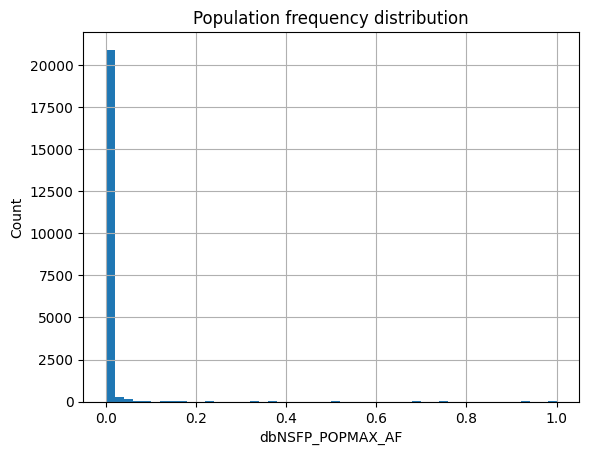

In [21]:
import matplotlib.pyplot as plt

df['dbNSFP_POPMAX_AF'].hist(bins=50)
plt.xlabel('dbNSFP_POPMAX_AF')
plt.ylabel('Count')
plt.title('Population frequency distribution')
plt.show()


In [22]:
# Keep missense variants in column Consequence
df_rare_unique_missense = df_rare_unique[df_rare_unique['Consequence'].str.contains('missense_variant')]

print(f"There are {len(df_rare_unique_missense)} missense SNVs.")


There are 556 missense SNVs.


## Binarization

In [23]:
# Extract infromation from the original dataset
from cyvcf2 import VCF

vcf_reader = VCF('../data/clinvar_bc_variants_for_vep.vcf')

records = []

for variant in vcf_reader:
    variant_id = variant.ID
    clnsig = variant.INFO.get('CLNSIG')

    records.append({
        'Uploaded_variation': variant_id,
        'ClinicalSignificance': clnsig
    })

clinvar_labels = pd.DataFrame(records)

print(clinvar_labels.head())
print(f"{len(clinvar_labels)} ClinVar labels are extracted.")


  Uploaded_variation          ClinicalSignificance
0             187213  Pathogenic/Likely_pathogenic
1             181942  Pathogenic/Likely_pathogenic
2            3148226                    Pathogenic
3             187275                    Pathogenic
4             188901  Pathogenic/Likely_pathogenic
12424 ClinVar labels are extracted.


In [26]:
# Merge rare variants and lables
## Check data type before mergeing
print(f"df_rare_unique_missense['Uploaded_variation'] dtype: {df_rare_unique_missense['Uploaded_variation'].dtype}")
print(f"clinvar_labels['Uploaded_variation'] dtype: {clinvar_labels['Uploaded_variation'].dtype}")


df_rare_unique_missense['Uploaded_variation'] dtype: int64
clinvar_labels['Uploaded_variation'] dtype: object


In [29]:
## Convert int64 to str
df_rare_unique_missense.loc[:, 'Uploaded_variation'] = df_rare_unique_missense['Uploaded_variation'].astype(str)
clinvar_labels['Uploaded_variation'] = clinvar_labels['Uploaded_variation'].astype(str)

In [ ]:
## Merge
df_merged = pd.merge(df_rare_unique_missense, clinvar_labels, on='Uploaded_variation', how='left')

print(f"There are {df_merged['ClinicalSignificance'].isna().sum()} variants without labels after merging.")

There are 1 variants without labels after merging.


In [36]:
# Binarization
## Define pathogenic and benign label sets
pathogenic_labels = ['Pathogenic', 'Likely_pathogenic', 'Pathogenic/Likely_pathogenic']
benign_labels = ['Benign', 'Likely_benign', 'Benign/Likely_benign']

def binarize_label(x):
    if pd.isna(x):
        return None
    x = str(x)
    if x in pathogenic_labels:
        return 1
    elif x in benign_labels:
        return 0
    else:
        return None  # VUS, Conflicting interpretations, Others

# Apply the binarization
df_merged['label'] = df_merged['ClinicalSignificance'].apply(binarize_label)

# Drop variants without a binary label
df_final = df_merged.dropna(subset=['label'])

print(f"There are {len(df_final)} variants with binary labels (0/1).")

# Save the final benchmark dataset
df_final.to_csv('../data/benchmark_dataset_raw.csv', index=False)

print("Benchmark dataset saved as benchmark_dataset.csv!")


There are 556 variants with binary labels (0/1).
Benchmark dataset saved as benchmark_dataset.csv!


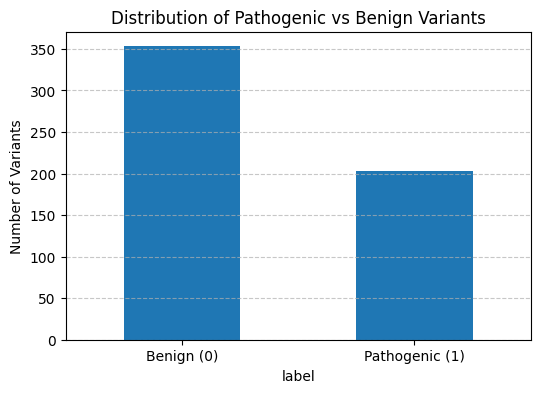

In [37]:
# Visualization

## Load data
df = pd.read_csv('../data/benchmark_dataset_raw.csv')

## Histgram of distribution
label_counts = df['label'].value_counts()

plt.figure(figsize=(6, 4))
label_counts.plot(kind='bar')
plt.xticks([0, 1], ['Benign (0)', 'Pathogenic (1)'], rotation=0)
plt.ylabel('Number of Variants')
plt.title('Distribution of Pathogenic vs Benign Variants')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()


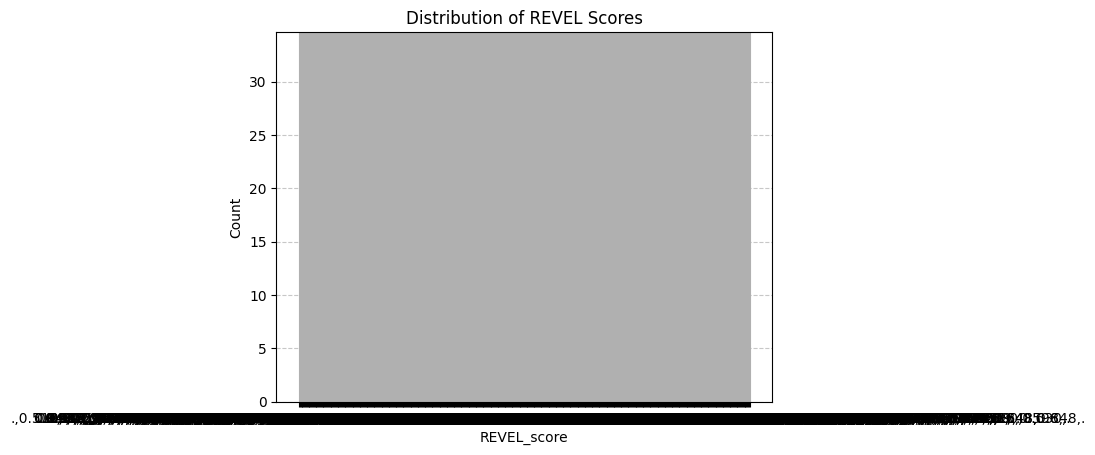

In [38]:
df['REVEL_score'].hist(bins=50)
plt.xlabel('REVEL_score')
plt.ylabel('Count')
plt.title('Distribution of REVEL Scores')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()


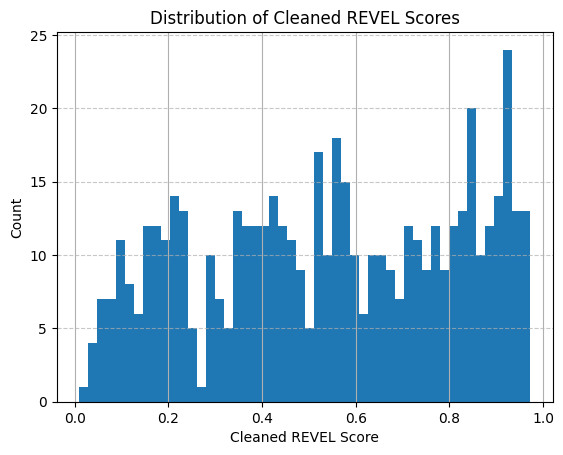

In [ ]:
def clean_revel(x):
    if pd.isna(x):
        return None
    items = str(x).split(',')
    numbers = []
    for i in items:
        if i not in ['.', '-', '']:
            try:
                numbers.append(float(i))
            except ValueError:
                continue
    if len(numbers) > 0:
        return numbers[0]
    else:
        return None


df['REVEL_score_clean'] = df['REVEL_score'].apply(clean_revel)


import matplotlib.pyplot as plt
df['REVEL_score_clean'].hist(bins=50)
plt.xlabel('Cleaned REVEL Score')
plt.ylabel('Count')
plt.title('Distribution of Cleaned REVEL Scores')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()


## Dataset Cleansing

In [40]:
# Load the raw dataset
df = pd.read_csv('../data/benchmark_dataset_raw.csv')

# Define cleasing function
def clean_score(x):
    if pd.isna(x):
        return None
    items = str(x).split(',')
    numbers = []
    for i in items:
        if i not in ['.', '-', '']:
            try:
                numbers.append(float(i))
            except ValueError:
                continue
    if len(numbers) > 0:
        return numbers[0]  # Reserve the first score
    else:
        return None

# Define score list
score_columns = [
    'SIFT_score', 'SIFT4G_score', 'PROVEAN_score', 'Polyphen2_HDIV_score', 'Polyphen2_HVAR_score',
    'MutationTaster_score', 'MutationAssessor_score', 'fathmm-XF_coding_score', 'CADD_raw',
    'VEST4_score', 'DANN_score', 'MetaSVM_score', 'MetaLR_score', 'MetaRNN_score',
    'Eigen-raw_coding', 'Eigen-PC-raw_coding', 'M-CAP_score', 'REVEL_score', 'MutPred_score',
    'MVP_score', 'gMVP_score', 'MPC_score', 'PrimateAI_score', 'DEOGEN2_score',
    'BayesDel_addAF_score', 'BayesDel_noAF_score', 'ClinPred_score', 'LIST-S2_score',
    'VARITY_R_score', 'VARITY_ER_score', 'VARITY_R_LOO_score', 'VARITY_ER_LOO_score',
    'ESM1b_score', 'AlphaMissense_score', 'PHACTboost_score', 'MutFormer_score', 'MutScore_score',
    'phyloP100way_vertebrate', 'phyloP470way_mammalian', 'phyloP17way_primate',
    'phastCons100way_vertebrate', 'phastCons470way_mammalian', 'phastCons17way_primate',
    'bStatistic', 'GERP++_RS', 'GERP_91_mammals', '1000Gp3_AF', 'gnomAD4.1_joint_AF',
    'TOPMed_frz8_AF', 'AllofUs_ALL_AF', 'RegeneronME_ALL_AF', 'dbNSFP_POPMAX_AF'
]

# Cleansing
for col in score_columns:
    if col in df.columns:
        print(f"Cleaning {col}...")
        df[col] = df[col].apply(clean_score) ## Avoid key error
    else:
        print(f"Warning: {col} not found in DataFrame, skipping.")

# Save the dataset
df.to_csv('../data/benchmark_dataset_cleaned.csv', index=False)

print("Cleaned dataset saved as benchmark_dataset_cleaned.csv")


Cleaning SIFT_score...
Cleaning SIFT4G_score...
Cleaning PROVEAN_score...
Cleaning Polyphen2_HDIV_score...
Cleaning Polyphen2_HVAR_score...
Cleaning MutationTaster_score...
Cleaning MutationAssessor_score...
Cleaning fathmm-XF_coding_score...
Cleaning CADD_raw...
Cleaning VEST4_score...
Cleaning DANN_score...
Cleaning MetaSVM_score...
Cleaning MetaLR_score...
Cleaning MetaRNN_score...
Cleaning Eigen-raw_coding...
Cleaning Eigen-PC-raw_coding...
Cleaning M-CAP_score...
Cleaning REVEL_score...
Cleaning MutPred_score...
Cleaning MVP_score...
Cleaning gMVP_score...
Cleaning MPC_score...
Cleaning PrimateAI_score...
Cleaning DEOGEN2_score...
Cleaning BayesDel_addAF_score...
Cleaning BayesDel_noAF_score...
Cleaning ClinPred_score...
Cleaning LIST-S2_score...
Cleaning VARITY_R_score...
Cleaning VARITY_ER_score...
Cleaning VARITY_R_LOO_score...
Cleaning VARITY_ER_LOO_score...
Cleaning ESM1b_score...
Cleaning AlphaMissense_score...
Cleaning PHACTboost_score...
Cleaning MutFormer_score...
Cleanin

## Impute missing value

In [42]:
# Load the dataset
df_cleaned = pd.read_csv('../data/benchmark_dataset_cleaned.csv')

# Missing value stastics
pd.set_option('display.max_rows', None)

missing_summary = df_cleaned.isnull().sum()

# Sort the result
missing_summary = missing_summary.sort_values(ascending=False)

print(missing_summary)


1000Gp3_AF                    462
MutPred_score                 261
TOPMed_frz8_AF                243
VARITY_ER_LOO_score           230
VARITY_R_score                230
VARITY_R_LOO_score            230
VARITY_ER_score               230
PHACTboost_score              229
LIST-S2_score                 214
AllofUs_ALL_AF                166
GERP_91_mammals               104
RegeneronME_ALL_AF             99
gnomAD4.1_joint_AF             84
MutationTaster_score           73
MutationAssessor_score         45
MPC_score                      36
PrimateAI_score                36
Polyphen2_HDIV_score           36
Polyphen2_HVAR_score           36
gMVP_score                     35
DEOGEN2_score                  34
PROVEAN_score                  26
SIFT_score                     26
REVEL_score                    26
M-CAP_score                    25
MutScore_score                 25
MutFormer_score                25
ESM1b_score                    24
SIFT4G_score                   23
ClinPred_score

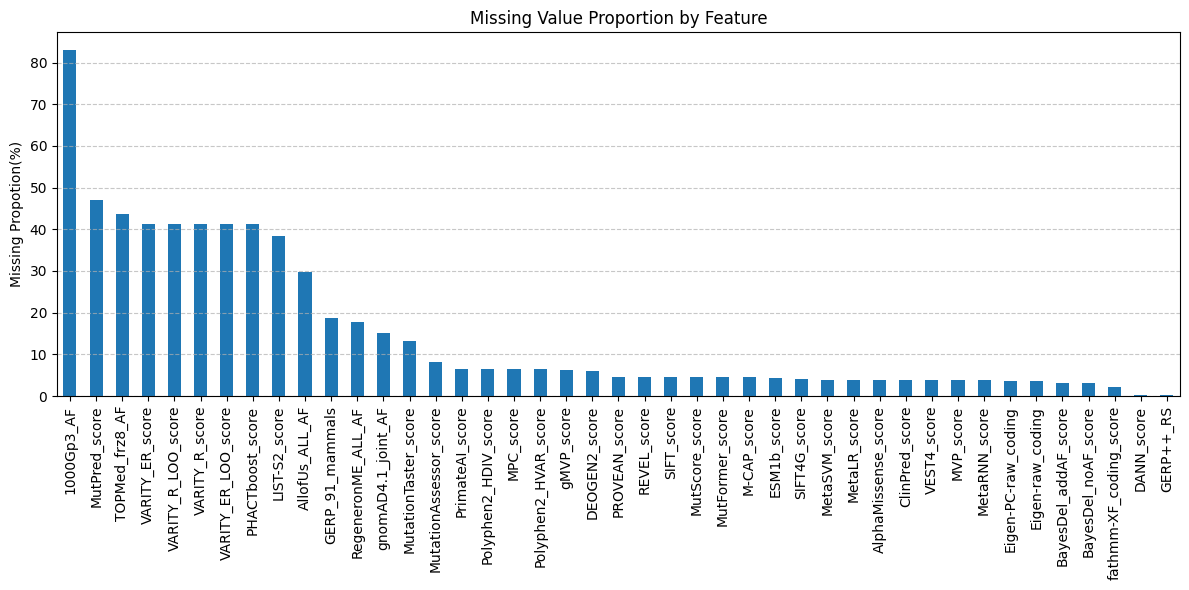

In [11]:
# Visualize the proportion of missing value in each column
import pandas as pd
import matplotlib.pyplot as plt

df_cleaned = pd.read_csv('../data/benchmark_dataset_cleaned.csv')

# Calculate the proportion
missing_proportion = df_cleaned.isnull().sum() / len(df_cleaned) * 100
missing_proportion = missing_proportion[missing_proportion > 0]
missing_proportion = missing_proportion.sort_values(ascending=False)

# Plot
plt.figure(figsize=(12, 6))
missing_proportion.plot(kind='bar')
plt.ylabel('Missing Propotion(%)')
plt.title('Missing Value Proportion by Feature')
plt.xticks(rotation=90)
plt.grid(axis= 'y', ls='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [12]:
# Drop columns with too many missing values
drop_cols = [
    '1000Gp3_AF', 'MutPred_score', 'TOPMed_frz8_AF',
    'VARITY_ER_score', 'VARITY_R_score', 'VARITY_R_LOO_score', 
    'VARITY_ER_LOO_score', 'PHACTboost_score', 'LIST-S2_score'
]

df_cleaned.drop(columns=drop_cols, inplace=True)

In [13]:
# Fill other missing values with median
fill_cols = [col for col in df_cleaned.columns if df_cleaned[col].isnull().sum() > 0]

for col in fill_cols:
    median_value = df_cleaned[col].median()
    df_cleaned[col] = df_cleaned[col].fillna(median_value)
    print(f"Filled missing values in '{col}' with median value.")

df_cleaned.to_csv('../data/benchmark_dataset_final.csv', index=False)

print("Saved final cleaned dataset as 'benchmark_dataset_final.csv'")

Filled missing values in 'AllofUs_ALL_AF' with median value.
Filled missing values in 'AlphaMissense_score' with median value.
Filled missing values in 'BayesDel_addAF_score' with median value.
Filled missing values in 'BayesDel_noAF_score' with median value.
Filled missing values in 'ClinPred_score' with median value.
Filled missing values in 'DANN_score' with median value.
Filled missing values in 'DEOGEN2_score' with median value.
Filled missing values in 'ESM1b_score' with median value.
Filled missing values in 'Eigen-PC-raw_coding' with median value.
Filled missing values in 'Eigen-raw_coding' with median value.
Filled missing values in 'GERP++_RS' with median value.
Filled missing values in 'GERP_91_mammals' with median value.
Filled missing values in 'M-CAP_score' with median value.
Filled missing values in 'MPC_score' with median value.
Filled missing values in 'MVP_score' with median value.
Filled missing values in 'MetaLR_score' with median value.
Filled missing values in 'Me